In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

In [2]:
# Load the data

In [3]:
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = Data.iloc[:, 0:]

In [4]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,...,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
0,73.82,13.55,13.21,15.13,14.11,0.66,0.10,42.63,42.63,42.63,...,0.00,0.00,0.31,-0.05,0.04,0.95,36.75,354.46,3.10,0
1,82.13,12.18,12.18,15.13,14.05,0.65,0.14,42.63,42.63,42.63,...,0.00,0.00,0.31,-0.05,0.04,0.95,36.76,354.45,3.09,0
2,72.87,13.72,0.00,21.96,15.89,9.92,0.00,35.69,0.00,35.69,...,16.82,0.00,0.35,0.00,0.05,0.94,40.99,2.07,6.89,0
3,70.52,14.18,0.00,21.96,14.72,8.41,0.09,35.69,35.69,35.69,...,17.84,0.00,0.35,0.00,0.05,0.94,41.06,2.23,6.94,0
4,71.60,13.97,0.00,21.96,14.21,7.47,0.05,28.15,28.15,35.69,...,16.48,0.00,0.35,0.00,0.05,0.93,41.08,2.41,7.02,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
287,15.67,63.83,16.39,63.83,41.04,13.82,1.04,63.78,52.00,63.78,...,17.09,0.00,0.07,-0.12,0.07,0.99,9.33,347.14,6.92,1
288,41.51,24.09,16.39,63.83,41.02,17.17,1.03,24.11,24.11,63.78,...,18.17,0.00,0.07,-0.12,0.07,0.99,9.46,347.23,7.19,1
289,18.12,55.18,16.39,63.83,41.04,18.73,1.39,55.18,24.11,55.18,...,18.58,0.00,0.08,-0.11,0.07,0.99,9.55,347.40,7.34,1
290,32.52,30.75,16.39,63.83,41.02,18.62,0.98,30.76,30.76,55.18,...,15.13,0.00,0.08,-0.11,0.07,0.99,9.69,347.56,7.33,1


In [5]:
# create new column "Labels" based on "FPS"
Data["Labels_two"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [6]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 292 entries, 0 to 291
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   FPS                      292 non-null    float64
 1   Frame Duration (ms)      292 non-null    float64
 2   Min Frame Duration (ms)  292 non-null    float64
 3   Max Frame Duration (ms)  292 non-null    float64
 4   Avg Frame Duration (ms)  292 non-null    float64
 5   Std Dev (ms)             292 non-null    float64
 6   Entropy Framerate        292 non-null    float64
 7   MotionToPhotonLatency    292 non-null    float64
 8   minMtpLatency            292 non-null    float64
 9   maxMtpLatency            292 non-null    float64
 10  avgMtpLatency            292 non-null    float64
 11  StdDev mtpLatency        292 non-null    float64
 12  mtpEntropy               292 non-null    float64
 13  currentRotation.x        292 non-null    float64
 14  currentRotation.y        2

In [7]:
Data.head(20)

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,...,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels,Labels_two
0,73.82,13.55,13.21,15.13,14.11,0.66,0.10,42.63,42.63,42.63,...,0.00,0.31,-0.05,0.04,0.95,36.75,354.46,3.10,0,0
1,82.13,12.18,12.18,15.13,14.05,0.65,0.14,42.63,42.63,42.63,...,0.00,0.31,-0.05,0.04,0.95,36.76,354.45,3.09,0,0
2,72.87,13.72,0.00,21.96,15.89,9.92,0.00,35.69,0.00,35.69,...,0.00,0.35,0.00,0.05,0.94,40.99,2.07,6.89,0,0
3,70.52,14.18,0.00,21.96,14.72,8.41,0.09,35.69,35.69,35.69,...,0.00,0.35,0.00,0.05,0.94,41.06,2.23,6.94,0,0
4,71.60,13.97,0.00,21.96,14.21,7.47,0.05,28.15,28.15,35.69,...,0.00,0.35,0.00,0.05,0.93,41.08,2.41,7.02,0,0
5,71.11,14.06,13.72,21.96,14.12,3.97,0.06,28.15,28.15,28.15,...,0.00,0.35,0.00,0.05,0.93,41.05,2.50,7.03,0,0
6,74.15,13.49,13.49,21.96,13.78,3.67,0.01,28.15,28.15,28.15,...,0.00,0.35,0.00,0.05,0.94,41.06,2.49,6.98,0,0
7,69.43,14.40,13.49,14.40,14.08,0.32,0.11,41.95,28.15,41.95,...,0.71,0.35,0.00,0.05,0.94,41.04,2.31,6.72,0,0
8,75.70,13.21,13.21,14.40,13.70,0.44,0.02,13.21,13.21,41.95,...,0.49,0.35,0.00,0.05,0.94,41.06,2.01,6.35,0,0
9,59.76,16.73,13.21,16.73,14.94,1.19,0.51,16.74,13.21,16.74,...,0.72,0.35,-0.01,0.04,0.94,41.10,1.54,5.83,0,1


In [8]:
Data.shape

(292, 22)

In [9]:
# Select input features and target variable

In [10]:
X = Data.iloc[:, 0 :]
X.drop(['Labels', 'Labels_two'], axis=1, inplace=True)

In [11]:
y = Data['Labels_two']

In [12]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [14]:
# Fit a random forest regressor and get the feature importances

In [15]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [16]:
print(f'model score on training data: {rf.score(X_train, y_train)}')
print(f'model score on testing data: {rf.score(X_test, y_test)}')

model score on training data: 0.9972094985250738
model score on testing data: 0.9346921658986175


In [17]:
importances_rf = rf.feature_importances_
indices = np.argsort(importances_rf)[::-1]

In [18]:
# Get feature names
feature_names_rf = X.columns

In [19]:
# Sort features by importance
indices = np.argsort(importances_rf)[::-1]

In [20]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances_rf[indices[f]], feature_names_rf[indices[f]]))

Feature ranking:
1. feature 1 (0.510000) - Frame Duration (ms)
2. feature 0 (0.430000) - FPS
3. feature 4 (0.040000) - Avg Frame Duration (ms)
4. feature 3 (0.020000) - Max Frame Duration (ms)
5. feature 18 (0.000000) - yaw
6. feature 2 (0.000000) - Min Frame Duration (ms)
7. feature 5 (0.000000) - Std Dev (ms)
8. feature 6 (0.000000) - Entropy Framerate
9. feature 7 (0.000000) - MotionToPhotonLatency
10. feature 8 (0.000000) - minMtpLatency
11. feature 19 (0.000000) - roll
12. feature 10 (0.000000) - avgMtpLatency
13. feature 11 (0.000000) - StdDev mtpLatency
14. feature 12 (0.000000) - mtpEntropy
15. feature 13 (0.000000) - currentRotation.x
16. feature 14 (0.000000) - currentRotation.y
17. feature 15 (0.000000) - currentRotation.z
18. feature 16 (0.000000) - currentRotation.w
19. feature 17 (0.000000) - pitch
20. feature 9 (0.000000) - maxMtpLatency


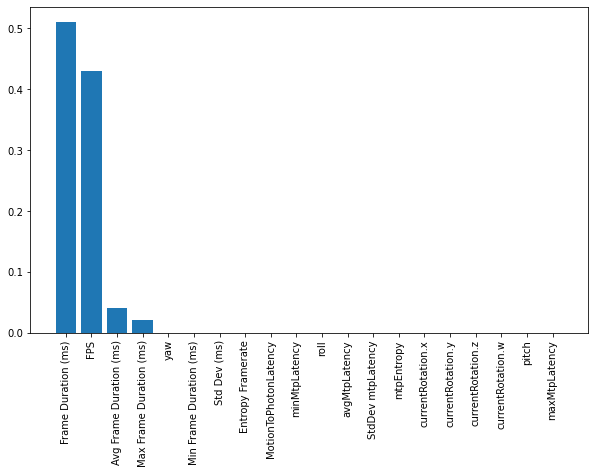

In [21]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances_rf)), importances_rf[indices])
plt.xticks(range(len(importances_rf)), feature_names_rf[indices], rotation=90)
plt.show()

In [22]:
# Calculate permutation importances

In [23]:
result = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)

In [24]:
# Print feature ranking
sorted_idx = result.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result.importances_mean[i]:.3f} +/- {result.importances_std[i]:.3f}")

Frame Duration (ms) 0.493 +/- 0.045
FPS             0.346 +/- 0.034
Avg Frame Duration (ms) 0.003 +/- 0.003
yaw             0.000 +/- 0.000
Min Frame Duration (ms) 0.000 +/- 0.000
Std Dev (ms)    0.000 +/- 0.000
Entropy Framerate 0.000 +/- 0.000
MotionToPhotonLatency 0.000 +/- 0.000
minMtpLatency   0.000 +/- 0.000
roll            0.000 +/- 0.000
avgMtpLatency   0.000 +/- 0.000
StdDev mtpLatency 0.000 +/- 0.000
mtpEntropy      0.000 +/- 0.000
currentRotation.x 0.000 +/- 0.000
currentRotation.y 0.000 +/- 0.000
currentRotation.z 0.000 +/- 0.000
currentRotation.w 0.000 +/- 0.000
pitch           0.000 +/- 0.000
maxMtpLatency   0.000 +/- 0.000
Max Frame Duration (ms) -0.001 +/- 0.001


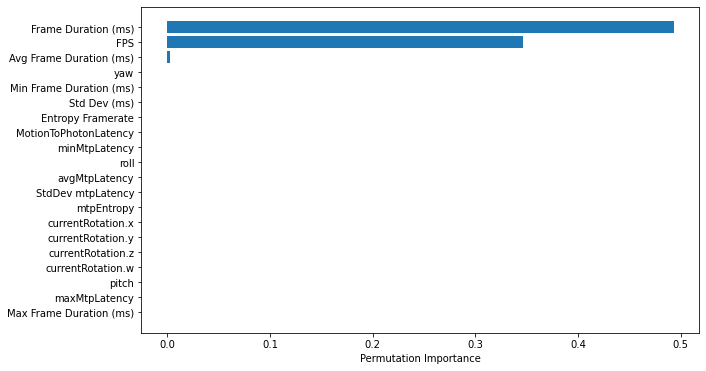

In [25]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [26]:
# Fit a linear regression model

In [27]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [28]:
print(f'model score on training data: {lr.score(X_train, y_train)}')
print(f'model score on testing data: {lr.score(X_test, y_test)}')

model score on training data: 0.9622377205941649
model score on testing data: 0.9263954196129162


In [29]:
# Get the coefficient values and feature names

In [30]:
coef_lr = lr.coef_

In [31]:
# Print the feature importance

In [32]:
feature_names_lr = X.columns

In [33]:
# Print the feature importance
print("Feature importance:")
for i in range(len(feature_names_lr)):
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
FPS: 0.249960
Frame Duration (ms): 0.066910
Min Frame Duration (ms): 0.062449
Max Frame Duration (ms): 0.478184
Avg Frame Duration (ms): 0.317360
Std Dev (ms): 0.210798
Entropy Framerate: 0.006598
MotionToPhotonLatency: 0.019254
minMtpLatency: 0.078386
maxMtpLatency: 0.008330
avgMtpLatency: 0.111954
StdDev mtpLatency: 0.412919
mtpEntropy: 0.004285
currentRotation.x: 0.142452
currentRotation.y: 0.045394
currentRotation.z: 0.010044
currentRotation.w: 0.004037
pitch: 0.049171
yaw: 0.009005
roll: 0.029425


In [34]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
Max Frame Duration (ms): 0.478184
StdDev mtpLatency: 0.412919
Avg Frame Duration (ms): 0.317360
FPS: 0.249960
Std Dev (ms): 0.210798
currentRotation.x: 0.142452
avgMtpLatency: 0.111954
minMtpLatency: 0.078386
Frame Duration (ms): 0.066910
Min Frame Duration (ms): 0.062449
pitch: 0.049171
currentRotation.y: 0.045394
roll: 0.029425
MotionToPhotonLatency: 0.019254
currentRotation.z: 0.010044
yaw: 0.009005
maxMtpLatency: 0.008330
Entropy Framerate: 0.006598
mtpEntropy: 0.004285
currentRotation.w: 0.004037


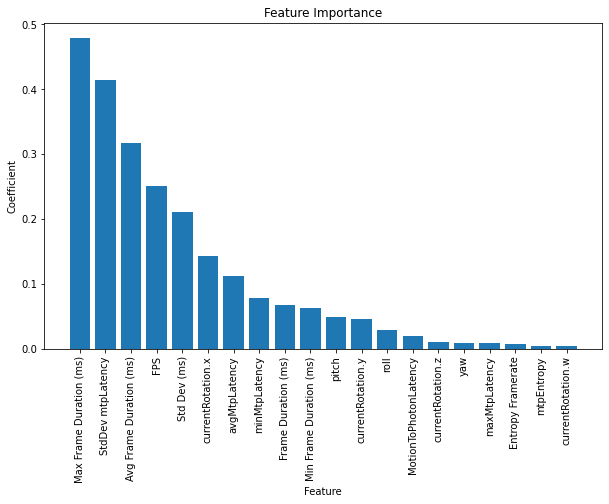

In [35]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names_lr[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [36]:
# Calculate permutation importances

In [37]:
result = permutation_importance(lr, X_test, y_test, n_repeats=10, random_state=42)

In [38]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lr[i], result.importances_mean[i]))

Permutation importances:
FPS: 0.459671
Avg Frame Duration (ms): 0.407825
currentRotation.x: 0.142827
avgMtpLatency: 0.060915
currentRotation.y: 0.028748
Max Frame Duration (ms): 0.020576
pitch: 0.019207
Min Frame Duration (ms): 0.011470
StdDev mtpLatency: 0.008068
roll: 0.005459
Std Dev (ms): 0.005226
minMtpLatency: 0.004420
Entropy Framerate: 0.001855
mtpEntropy: 0.000754
Frame Duration (ms): 0.000535
MotionToPhotonLatency: 0.000231
maxMtpLatency: 0.000059
currentRotation.w: -0.000150
yaw: -0.000492
currentRotation.z: -0.000653


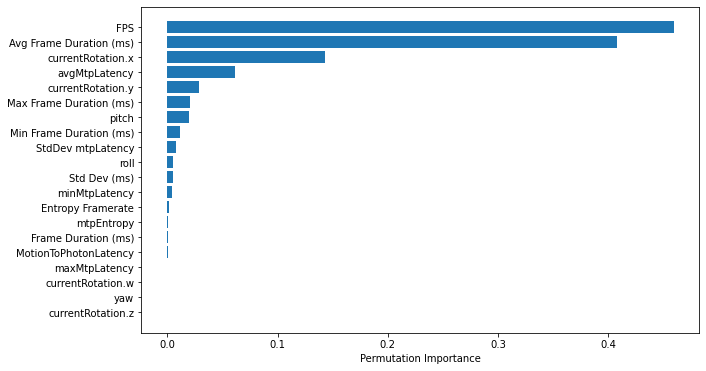

In [39]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [40]:
# Fit a Logistic Regression model

In [41]:
lor = LogisticRegression(max_iter= 1000)
lor.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [42]:
print(f'model score on training data: {lor.score(X_train, y_train)}')
print(f'model score on testing data: {lor.score(X_test, y_test)}')

model score on training data: 0.9914163090128756
model score on testing data: 0.9830508474576272


In [43]:
# Get the coefficient values and feature names

In [44]:
coef_lor = lor.coef_[0]
feature_names_lor = X.columns

In [45]:
# Print the feature names and their absolute coefficient values in descending order
for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1]):
    print("%s: %f" % (name, value))

FPS: 2.613855
currentRotation.x: 1.143647
Avg Frame Duration (ms): 1.033484
Entropy Framerate: 0.566371
currentRotation.w: 0.551676
roll: 0.522022
Min Frame Duration (ms): 0.387552
avgMtpLatency: 0.282430
yaw: 0.267023
mtpEntropy: 0.266059
currentRotation.z: 0.205047
currentRotation.y: 0.165921
Max Frame Duration (ms): 0.118910
Std Dev (ms): 0.117181
Frame Duration (ms): 0.116309
pitch: 0.115549
minMtpLatency: 0.092996
maxMtpLatency: 0.081690
MotionToPhotonLatency: 0.073036
StdDev mtpLatency: 0.060146


In [46]:
# Sort features by absolute coefficient value
sorted_features = [name for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]
sorted_coefs = [value for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]

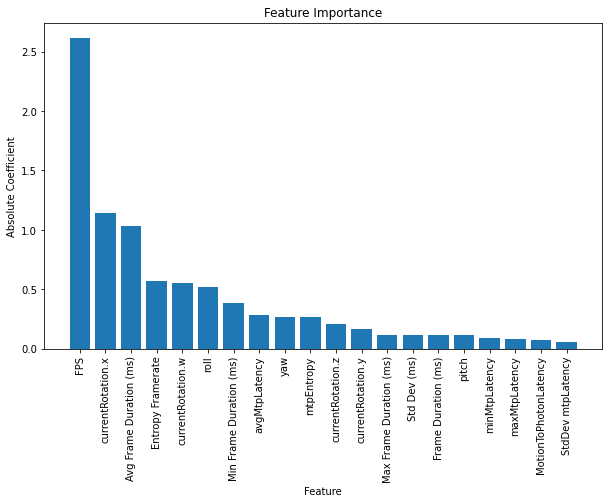

In [47]:
# Create bar plot of feature importance
plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefs)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Absolute Coefficient')
plt.title('Feature Importance')
plt.show()

In [48]:
# Calculate permutation importances

In [49]:
result = permutation_importance(lor, X_test, y_test, n_repeats=10, random_state=42)

In [50]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lor[i], result.importances_mean[i]))

Permutation importances:
FPS: 0.272881
currentRotation.w: 0.001695
currentRotation.x: 0.001695
minMtpLatency: 0.000000
Frame Duration (ms): 0.000000
Min Frame Duration (ms): 0.000000
Max Frame Duration (ms): 0.000000
Avg Frame Duration (ms): 0.000000
Std Dev (ms): 0.000000
Entropy Framerate: 0.000000
MotionToPhotonLatency: 0.000000
roll: 0.000000
yaw: 0.000000
avgMtpLatency: 0.000000
StdDev mtpLatency: 0.000000
mtpEntropy: 0.000000
currentRotation.y: 0.000000
currentRotation.z: 0.000000
pitch: 0.000000
maxMtpLatency: 0.000000


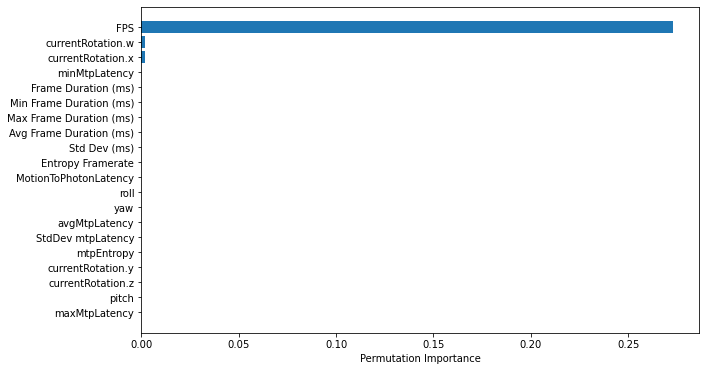

In [51]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [52]:
#Decision tree-based 

In [53]:
# Train a decision tree classifier on the original dataset

In [54]:
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [55]:
print(f'model score on training data: {clf.score(X_train, y_train)}')
print(f'model score on testing data: {clf.score(X_test, y_test)}')

model score on training data: 1.0
model score on testing data: 0.9830508474576272


In [56]:
# Plot the feature importance

In [57]:
importance_clf = clf.feature_importances_
feature_names_clf = X.columns

In [58]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': importance_clf})

In [59]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                    Feature  Importance
1       Frame Duration (ms)         1.0
0                       FPS         0.0
18                      yaw         0.0
17                    pitch         0.0
16        currentRotation.w         0.0
15        currentRotation.z         0.0
14        currentRotation.y         0.0
13        currentRotation.x         0.0
12               mtpEntropy         0.0
11        StdDev mtpLatency         0.0
10            avgMtpLatency         0.0
9             maxMtpLatency         0.0
8             minMtpLatency         0.0
7     MotionToPhotonLatency         0.0
6         Entropy Framerate         0.0
5              Std Dev (ms)         0.0
4   Avg Frame Duration (ms)         0.0
3   Max Frame Duration (ms)         0.0
2   Min Frame Duration (ms)         0.0
19                     roll         0.0


In [60]:
sorted_idx = importance_clf.argsort()

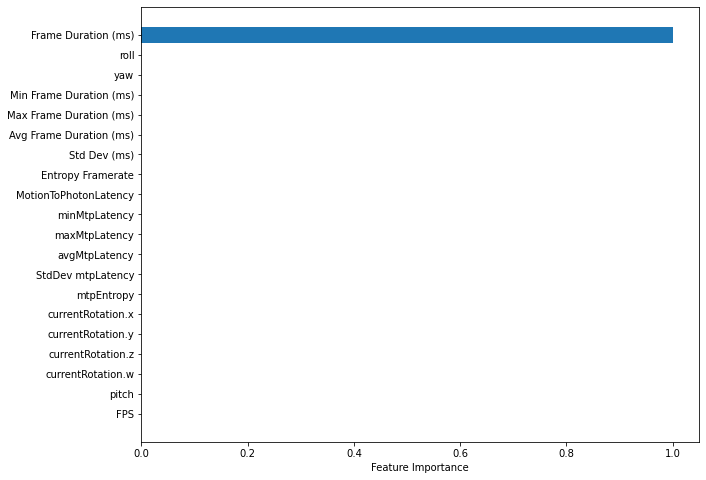

In [61]:
plt.figure(figsize = (10, 8))
plt.barh(range(len(sorted_idx)), importance_clf[sorted_idx])
plt.yticks(range(len(sorted_idx)), [feature_names_clf[i] for i in sorted_idx])
plt.xlabel('Feature Importance')
plt.show()

In [62]:
# Calculate permutation importance
perm_importance = permutation_importance(clf, X_train, y_train, n_repeats=10, random_state=42)

In [63]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})

In [64]:
feature_importance

,Feature,Importance
0,FPS,0.000000
1,Frame Duration (ms),0.502146
2,Min Frame Duration (ms),0.000000
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.000000
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.000000
7,MotionToPhotonLatency,0.000000
8,minMtpLatency,0.000000
9,maxMtpLatency,0.000000


In [65]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                    Feature  Importance
1       Frame Duration (ms)    0.502146
0                       FPS    0.000000
18                      yaw    0.000000
17                    pitch    0.000000
16        currentRotation.w    0.000000
15        currentRotation.z    0.000000
14        currentRotation.y    0.000000
13        currentRotation.x    0.000000
12               mtpEntropy    0.000000
11        StdDev mtpLatency    0.000000
10            avgMtpLatency    0.000000
9             maxMtpLatency    0.000000
8             minMtpLatency    0.000000
7     MotionToPhotonLatency    0.000000
6         Entropy Framerate    0.000000
5              Std Dev (ms)    0.000000
4   Avg Frame Duration (ms)    0.000000
3   Max Frame Duration (ms)    0.000000
2   Min Frame Duration (ms)    0.000000
19                     roll    0.000000


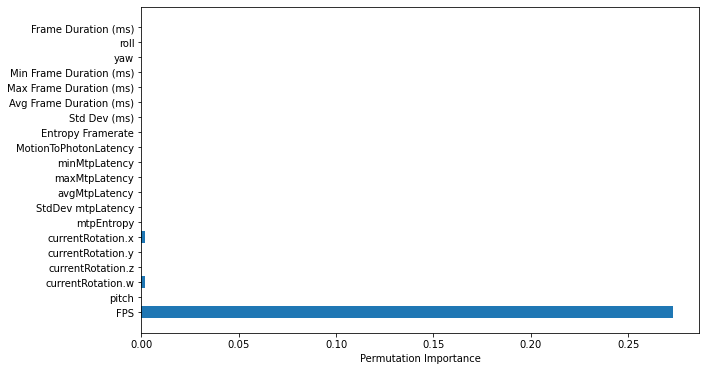

In [66]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [67]:
#Lasso regression

In [68]:
# Train a Lasso regression model on the original dataset

In [69]:
Lasso = Lasso(alpha=0.1)
Lasso.fit(X_train, y_train)

Lasso(alpha=0.1)

In [70]:
Lasso.fit(X_train, y_train)

Lasso(alpha=0.1)

In [71]:
print(f'model score on training data: {Lasso.score(X_train, y_train)}')
print(f'model score on testing data: {Lasso.score(X_test, y_test)}')

model score on training data: 0.8743321829973508
model score on testing data: 0.8113819509697322


In [72]:
# Get the absolute value of the regression coefficients

In [73]:
Lasso_abs = abs(Lasso.coef_)

In [74]:
Lasso_abs

array([0.35522767, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.02844693, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

In [75]:
# Create a DataFrame to store the feature importance scores and names

In [76]:
feature_importance_Lasso = pd.DataFrame({'Feature_names': X.columns, 'Importance':Lasso_abs})

In [77]:
# Sort the features by importance and print the ranked list

In [78]:
feature_importance_Lasso = feature_importance_Lasso.sort_values('Importance', ascending=False)

In [79]:
feature_importance_Lasso

,Feature_names,Importance
0,FPS,0.355228
13,currentRotation.x,0.028447
1,Frame Duration (ms),0.000000
18,yaw,0.000000
17,pitch,0.000000
16,currentRotation.w,0.000000
15,currentRotation.z,0.000000
14,currentRotation.y,0.000000
12,mtpEntropy,0.000000
11,StdDev mtpLatency,0.000000


In [80]:
# Create a barplot of the feature importance scores>

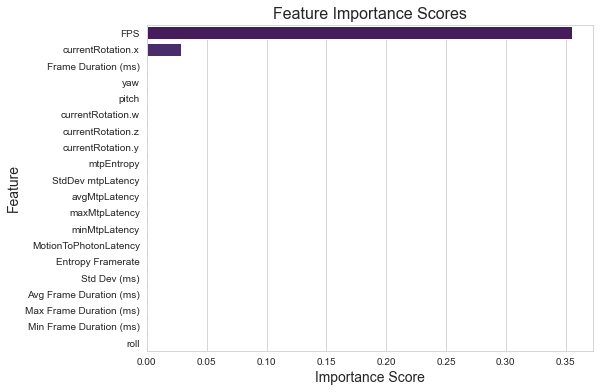

In [81]:
plt.figure(figsize=(8, 6))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance_Lasso, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [82]:
# Calculate permutation importance
perm_importance_Lasso = permutation_importance(Lasso, X_train, y_train, n_repeats=10, random_state=42)

In [83]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})

In [84]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                    Feature  Importance
1       Frame Duration (ms)    0.502146
0                       FPS    0.000000
18                      yaw    0.000000
17                    pitch    0.000000
16        currentRotation.w    0.000000
15        currentRotation.z    0.000000
14        currentRotation.y    0.000000
13        currentRotation.x    0.000000
12               mtpEntropy    0.000000
11        StdDev mtpLatency    0.000000
10            avgMtpLatency    0.000000
9             maxMtpLatency    0.000000
8             minMtpLatency    0.000000
7     MotionToPhotonLatency    0.000000
6         Entropy Framerate    0.000000
5              Std Dev (ms)    0.000000
4   Avg Frame Duration (ms)    0.000000
3   Max Frame Duration (ms)    0.000000
2   Min Frame Duration (ms)    0.000000
19                     roll    0.000000


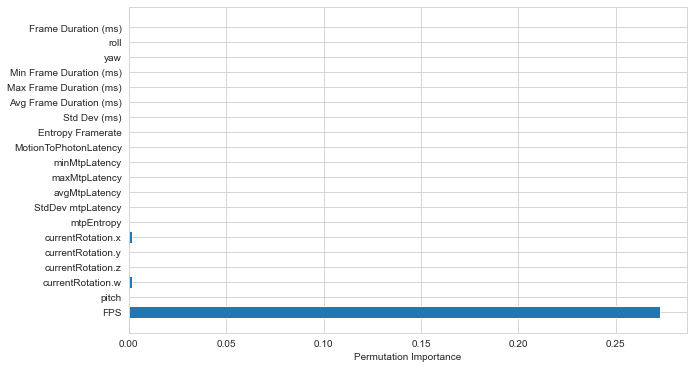

In [85]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [86]:
#XGBClassifier

In [87]:
from xgboost import XGBClassifier

In [88]:
# Instantiate XGBClassifier with default hyperparameters

In [89]:
xgb = XGBClassifier()
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

In [90]:
# Use the built-in feature importance method to get feature importance scores
feat_importances_xgb = xgb.feature_importances_

In [91]:
feat_importances_xgb

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.], dtype=float32)

In [92]:
# Create a dictionary mapping feature names to importance scores
feat_importances_dict = {feat: score for feat, score in zip(X.columns, feat_importances_xgb)}

In [93]:
feat_importances_dict

{'FPS': 1.0,
 'Frame Duration (ms)': 0.0,
 'Min Frame Duration (ms)': 0.0,
 'Max Frame Duration (ms)': 0.0,
 'Avg Frame Duration (ms)': 0.0,
 'Std Dev (ms)': 0.0,
 'Entropy Framerate': 0.0,
 'MotionToPhotonLatency': 0.0,
 'minMtpLatency': 0.0,
 'maxMtpLatency': 0.0,
 'avgMtpLatency': 0.0,
 'StdDev mtpLatency': 0.0,
 'mtpEntropy': 0.0,
 'currentRotation.x': 0.0,
 'currentRotation.y': 0.0,
 'currentRotation.z': 0.0,
 'currentRotation.w': 0.0,
 'pitch': 0.0,
 'yaw': 0.0,
 'roll': 0.0}

In [94]:
# Sort the ditionary in descending order of importance score
sorted_feat_importances = sorted(feat_importances_dict.items(), key=lambda x: x[1], reverse=True)

In [95]:
# Print the sorted feature importance scores
for feat, score in sorted_feat_importances:
    print(f'{feat}: {score}')

FPS: 1.0
Frame Duration (ms): 0.0
Min Frame Duration (ms): 0.0
Max Frame Duration (ms): 0.0
Avg Frame Duration (ms): 0.0
Std Dev (ms): 0.0
Entropy Framerate: 0.0
MotionToPhotonLatency: 0.0
minMtpLatency: 0.0
maxMtpLatency: 0.0
avgMtpLatency: 0.0
StdDev mtpLatency: 0.0
mtpEntropy: 0.0
currentRotation.x: 0.0
currentRotation.y: 0.0
currentRotation.z: 0.0
currentRotation.w: 0.0
pitch: 0.0
yaw: 0.0
roll: 0.0


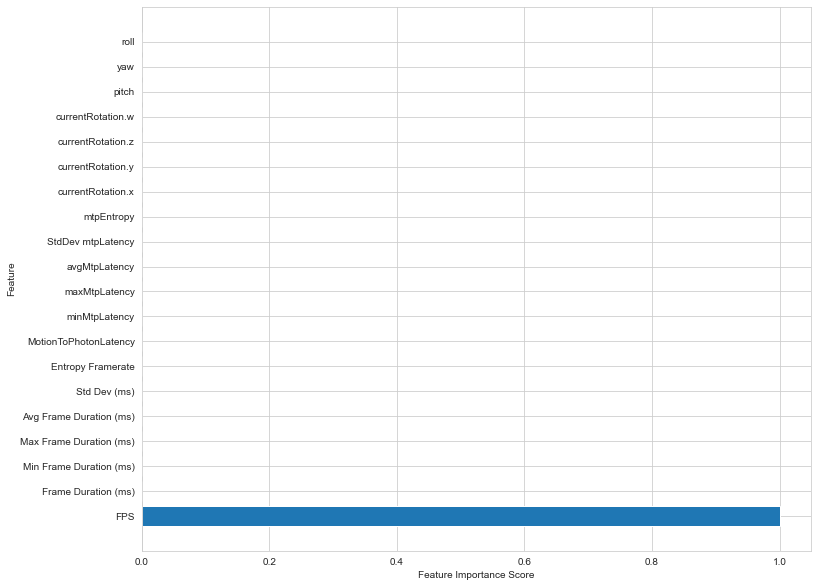

In [96]:
# Plot the feature importance scores as a horizontal bar chart
plt.figure(figsize = (12, 10))
plt.barh(range(len(feat_importances_xgb)), feat_importances_xgb)
plt.yticks(range(len(feat_importances_xgb)), X.columns)
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.show()

In [97]:
# Calculate permutation importance
perm_importance_xgb = permutation_importance(xgb, X_train, y_train, n_repeats=10, random_state=42)

In [98]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})
feature_importance 

,Feature,Importance
0,FPS,0.000000
1,Frame Duration (ms),0.502146
2,Min Frame Duration (ms),0.000000
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.000000
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.000000
7,MotionToPhotonLatency,0.000000
8,minMtpLatency,0.000000
9,maxMtpLatency,0.000000


In [99]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                    Feature  Importance
1       Frame Duration (ms)    0.502146
0                       FPS    0.000000
18                      yaw    0.000000
17                    pitch    0.000000
16        currentRotation.w    0.000000
15        currentRotation.z    0.000000
14        currentRotation.y    0.000000
13        currentRotation.x    0.000000
12               mtpEntropy    0.000000
11        StdDev mtpLatency    0.000000
10            avgMtpLatency    0.000000
9             maxMtpLatency    0.000000
8             minMtpLatency    0.000000
7     MotionToPhotonLatency    0.000000
6         Entropy Framerate    0.000000
5              Std Dev (ms)    0.000000
4   Avg Frame Duration (ms)    0.000000
3   Max Frame Duration (ms)    0.000000
2   Min Frame Duration (ms)    0.000000
19                     roll    0.000000


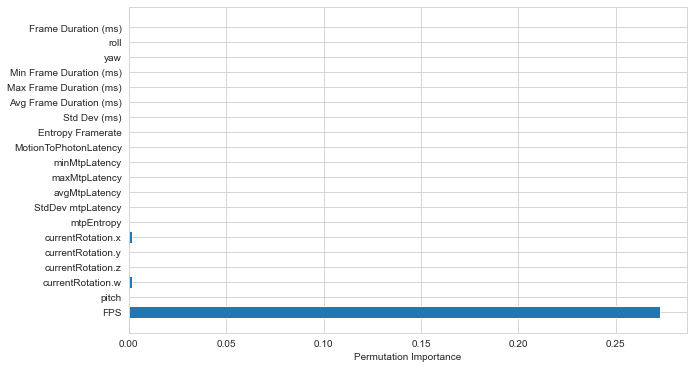

In [100]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [101]:
#Elastic Net Feature Importance

In [102]:
from sklearn.linear_model import ElasticNetCV

# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=0)

# Fit the model on training data
enet.fit(X_train, y_train)

# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])


FPS :  0.35481193485477763
currentRotation.x :  0.17855140373476616
Avg Frame Duration (ms) :  0.16221204657107394
Min Frame Duration (ms) :  0.06561058906553435
pitch :  0.06425639986022082
StdDev mtpLatency :  0.040928663657723276
currentRotation.y :  0.035605004570231365
roll :  0.028070651182723633
Entropy Framerate :  0.026207161251617622
Std Dev (ms) :  0.021516383231577896
minMtpLatency :  0.01483686450074137
currentRotation.z :  0.006021564741922908
currentRotation.w :  0.0013713327770892908
Frame Duration (ms) :  0.0
Max Frame Duration (ms) :  0.0
MotionToPhotonLatency :  0.0
maxMtpLatency :  0.0
avgMtpLatency :  0.0
mtpEntropy :  0.0
yaw :  0.0


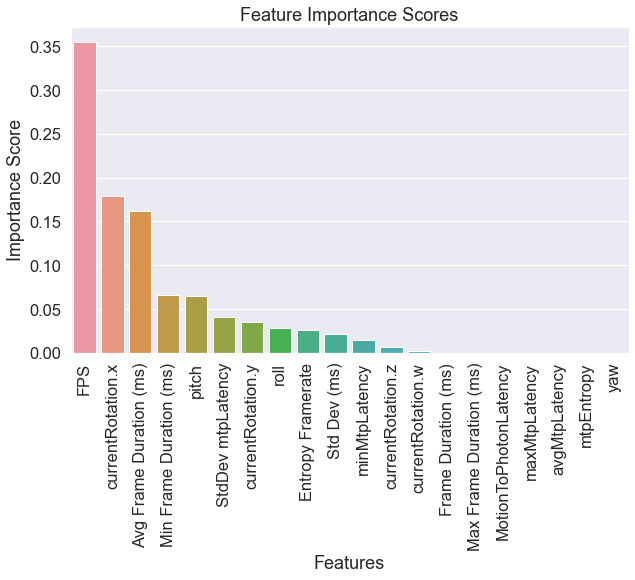

In [103]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [104]:
# Calculate permutation importance
perm_importance_enet = permutation_importance(enet, X_train, y_train, n_repeats=10, random_state=42)

In [105]:
# Create a DataFrame to store the feature importance scores and names
feature_importance_enet = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_enet.importances_mean})
feature_importance_enet

,Feature,Importance
0,FPS,0.761106
1,Frame Duration (ms),0.000000
2,Min Frame Duration (ms),0.026406
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.160670
5,Std Dev (ms),0.002997
6,Entropy Framerate,0.004137
7,MotionToPhotonLatency,0.000000
8,minMtpLatency,0.001764
9,maxMtpLatency,0.000000


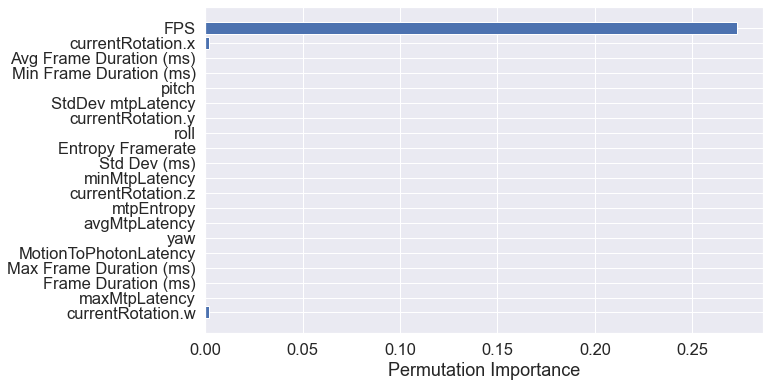

In [106]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [107]:
# Ridge model

In [108]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [109]:
# Predict on the testing data
y_pred = ridge.predict(X_test)

In [110]:
from sklearn.metrics import mean_squared_error

In [111]:
# Evaluate the model performance on testing data
mse = mean_squared_error(y_test, y_pred)
print("Mean squared error:", mse)

Mean squared error: 0.01853648179205493


In [112]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [113]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [114]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [115]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [116]:
sorted_features

[('FPS', 0.21745803849796377),
 ('Avg Frame Duration (ms)', 0.21086736357495345),
 ('currentRotation.x', 0.12134468804360407),
 ('StdDev mtpLatency', 0.08936652668916517),
 ('avgMtpLatency', 0.05851232501437863),
 ('Min Frame Duration (ms)', 0.04653316207831329),
 ('pitch', 0.04640091730802401),
 ('minMtpLatency', 0.04199795683671643),
 ('Std Dev (ms)', 0.0398608646452937),
 ('currentRotation.y', 0.037693007293008035),
 ('roll', 0.023702237404081103),
 ('Max Frame Duration (ms)', 0.012526995115653177),
 ('currentRotation.z', 0.01189510335435015),
 ('Frame Duration (ms)', 0.010169648640682875),
 ('Entropy Framerate', 0.009089084678139516),
 ('MotionToPhotonLatency', 0.00843313392313489),
 ('yaw', 0.005727876841034547),
 ('mtpEntropy', 0.004122102647283664),
 ('maxMtpLatency', 0.002939465588267622),
 ('currentRotation.w', 0.001359501825951943)]

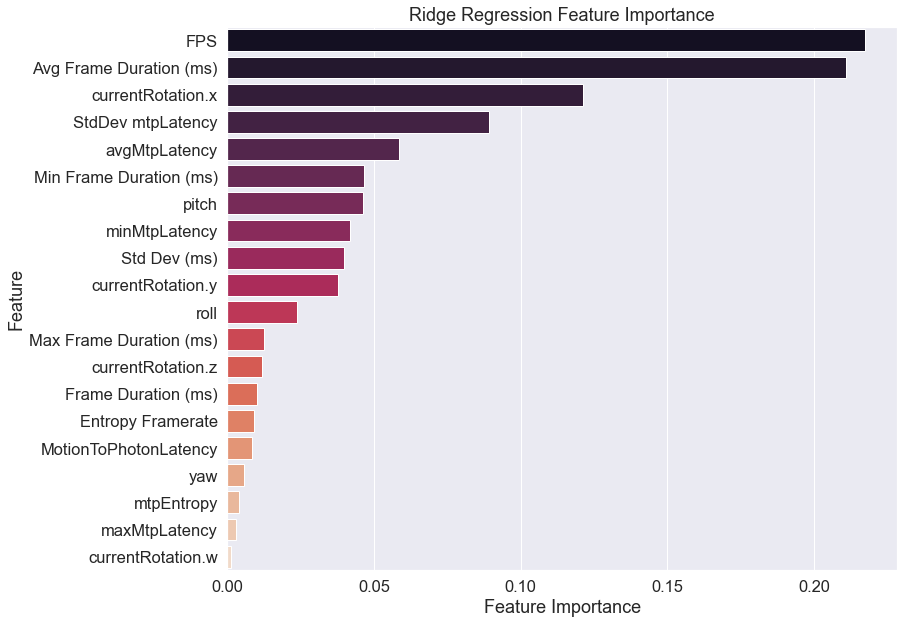

In [117]:
plt.figure(figsize = (12, 10))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [118]:
#shap

In [119]:
import shap

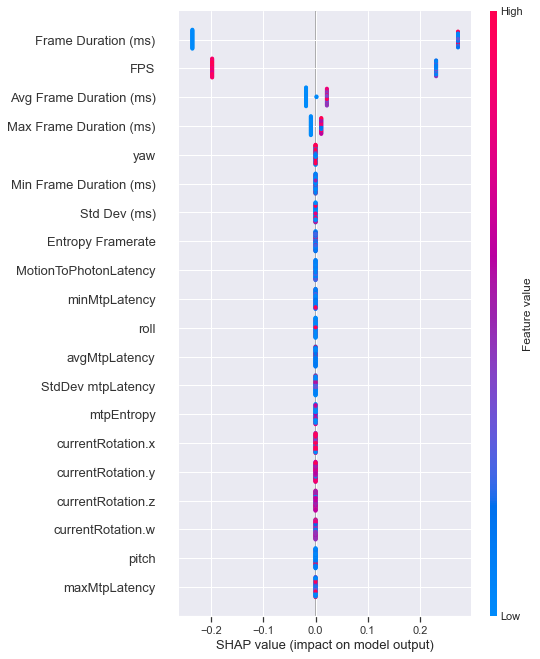

In [120]:
# Train a random forest regressor model
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

# Calculate Shapley value feature importance
explainer = shap.Explainer(rf.predict, X_train)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test, feature_names=X.columns)